<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/LAB_CJCS_02_NATIVE_SUCUPIRA_CPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CJCS LAB 02 — Native Sucupira research metadata
**CPU · original CAPES JSON/JSONL · reversible hierarchical normalization · comparison with conventional flattening**

Pilot investigation. This laboratory does **not** assume native exports are present, does **not** contact the API or recalculate embeddings, and will **not** report publication-ready statistical findings before the experiment runs. Source files remain read-only.

**Scientific question:** How much hierarchical fidelity and computational cost are incurred when original nested research-metadata records are transformed into tabular forms?

In [ ]:
# 01 — Environment and paths (CPU)
%pip -q install pandas pyarrow duckdb numpy matplotlib
from pathlib import Path
from collections import Counter, defaultdict
import os, re, json, gzip, hashlib, time, random, math, tracemalloc, statistics
import pandas as pd
import numpy as np
from IPython.display import display
try:
 from google.colab import drive
 drive.mount('/content/drive')
except ImportError:
 print('Not in Colab; checking local mounted paths.')
SOURCE = Path('/content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL')
OUTPUT = Path('/content/drive/MyDrive/CAPES_Epistemic_Change/106_CJCS_NATIVE_SUCUPIRA_RELATIONALIZATION_V1')
OUTPUT.mkdir(parents=True,exist_ok=True)
assert SOURCE.is_dir(), f'Original Sucupira acquisition directory missing: {SOURCE}'
print('Original source:',SOURCE,'\nNew output:',OUTPUT,'\nCPU only')

Mounted at /content/drive
Original source: /content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL 
New output: /content/drive/MyDrive/CAPES_Epistemic_Change/106_CJCS_NATIVE_SUCUPIRA_RELATIONALIZATION_V1 
CPU only


In [ ]:
# 02 — Discover original native records, without inventing a schema
# Search ONLY the native extraction partition tree documented by the attached Sucupira notebook.
NATIVE = SOURCE/'10_producao_2024_final'/'01_particoes'
assert NATIVE.is_dir(), f'No native partition directory: {NATIVE}'
allowed={'.json','.jsonl','.ndjson','.gz'}
files=sorted(p for p in NATIVE.rglob('*') if p.is_file() and (p.suffix.lower() in allowed))
rows=[]
for p in files:
 rel=str(p.relative_to(NATIVE))
 if p.name.startswith('_') or p.name.endswith('.tmp'):continue
 rows.append(dict(path=str(p),relative=rel,bytes=p.stat().st_size,suffix=p.suffix))
manifest=pd.DataFrame(rows)
manifest.to_csv(OUTPUT/'01_NATIVE_SOURCE_INVENTORY.csv',index=False)
print('Candidate native files:',len(manifest),'total bytes:',int(manifest.bytes.sum()) if len(manifest) else 0)
display(manifest.head(20))
assert len(manifest)>0,'No actual native JSON/JSONL files found. No surrogate data substituted.'

Candidate native files: 2025 total bytes: 7176154


,path,relative,bytes,suffix
0,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=050f18473d2ea089f402b9b6/...,727,.gz
1,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=050f18473d2ea089f402b9b6/...,119,.json
2,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=064169d05745c6f8e14a66b2/...,738,.gz
3,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=064169d05745c6f8e14a66b2/...,119,.json
4,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0658cbaa427049013c9eedf4/...,5818,.gz
5,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0658cbaa427049013c9eedf4/...,121,.json
6,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0658cbaa427049013c9eedf4/...,2117,.gz
7,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0658cbaa427049013c9eedf4/...,120,.json
8,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0705fe08005ee796bcd1dccf/...,1060,.gz
9,/content/drive/MyDrive/CAPES_Sucupira_Producoe...,ano=2024/tipo=1/part=0705fe08005ee796bcd1dccf/...,120,.json


In [ ]:
# 03 — Strict native JSON reader; deliberately bounded, deterministic pilot
# File names and dataset paths are recorded, not guessed. Page/checkpoint metadata are excluded.
def json_records(path):
 opener=gzip.open if str(path).lower().endswith('.gz') else open
 with opener(path,'rt',encoding='utf-8') as fp:
  first=fp.read(1);fp.seek(0)
  if first=='[':
   data=json.load(fp)
   assert isinstance(data,list),'Expected JSON list'
   for x in data:
    if isinstance(x,dict):yield x
  elif first=='{':
   # JSON lines are common in captured pages; a standalone JSON object is also accepted.
   firstline=fp.readline();secondline=fp.readline();fp.seek(0)
   if secondline.strip():
    for line in fp:
     if line.strip():
      obj=json.loads(line)
      if isinstance(obj,dict):yield obj
   else:
    x=json.load(fp)
    if isinstance(x,dict) and isinstance(x.get('content'),list):
     yield from (v for v in x['content'] if isinstance(v,dict))
    elif isinstance(x,dict):yield x
  else:
   for line in fp:
    if line.strip():
     x=json.loads(line)
     if isinstance(x,dict):yield x

MAX_RECORDS=3000; MAX_FILES=1500
records=[];loc=[];errors=[]
for path in manifest.path.iloc[:MAX_FILES]:
 if len(records)>=MAX_RECORDS:break
 try:
  for offset,rec in enumerate(json_records(Path(path))):
   records.append(rec);loc.append((path,offset))
   if len(records)>=MAX_RECORDS:break
 except (OSError,UnicodeError,ValueError,json.JSONDecodeError) as e:
  errors.append({'path':path,'error':repr(e)})
pd.DataFrame(errors,columns=['path','error']).to_csv(OUTPUT/'02_NATIVE_PARSE_ERRORS.csv',index=False)
assert records, 'No genuine CAPES production JSON objects could be parsed. See parse-errors CSV.'
print('Original sampled records:',len(records),'files sampled:',len(set(p for p,_ in loc)),'errors:',len(errors))
print('Actual top-level keys:',sorted(set().union(*(r.keys() for r in records)))[:80])

Original sampled records: 3000 files sampled: 111 errors: 110
Actual top-level keys: ['anoBase', 'autores', 'dataPublicacao', 'id', 'nomeProducao', 'nomePrograma', 'nomeSubTipoProducao', 'nomeTipoProducao', 'siglaIes']


In [ ]:
# 04 — Reproducible sample hashes, structural profile, actual field types
# No identifiers/person-level information are exported from the sampled source.
def canonical(x):return json.dumps(x,sort_keys=True,ensure_ascii=False,separators=(',',':'),allow_nan=False)
def digest(x):return hashlib.sha256(canonical(x).encode()).hexdigest()
orig_hashes=[digest(x) for x in records]
def walk(x,prefix=()):
 if isinstance(x,dict):
  yield prefix,'dict',len(x)
  for k,v in x.items():yield from walk(v,prefix+(str(k),))
 elif isinstance(x,list):
  yield prefix,'list',len(x)
  for v in x:yield from walk(v,prefix+('[]',))
 else:yield prefix,type(x).__name__,1
profile=Counter((('.'.join(path) or '$'),typ) for r in records for path,typ,_ in walk(r))
prof=pd.DataFrame([{'path':p,'data_type':t,'occurrences':v} for (p,t),v in profile.items()]).sort_values('occurrences',ascending=False)
prof.to_csv(OUTPUT/'03_NATIVE_PATH_TYPE_PROFILE.csv',index=False)
display(prof.head(30))
print('Records with nested containers:',sum(any(isinstance(v,(dict,list)) for v in r.values()) for r in records))

,path,data_type,occurrences
9,autores.[].ordem,int,4778
8,autores.[],dict,4778
12,autores.[].tipoVinculo,str,4778
11,autores.[].nomePessoa,str,4778
10,autores.[].idPessoa,int,4561
13,autores.[].grauAcademico,NoneType,3309
1,id,int,3000
0,$,dict,3000
2,nomeProducao,str,3000
3,anoBase,int,3000


Records with nested containers: 3000


In [ ]:
# 05 — Fully typed reversible leaf representation (generic JSON -> path/value tree)
# Path token types preserve object keys separately from list indices; empty containers and nulls retained.
def encode_tree(obj):
 out=[]
 def visit(x,path):
  if isinstance(x,dict):
   out.append((path,'object',None))
   for k,v in x.items(): visit(v,path+(('key',k),))
  elif isinstance(x,list):
   out.append((path,'array',None))
   for i,v in enumerate(x):visit(v,path+(('index',i),))
  elif x is None:out.append((path,'null',None))
  elif isinstance(x,bool):out.append((path,'bool',x))
  elif isinstance(x,int):out.append((path,'int',x))
  elif isinstance(x,float):out.append((path,'float',x))
  elif isinstance(x,str):out.append((path,'string',x))
  else:raise TypeError(type(x))
 visit(obj,())
 return out

def decode_tree(nodes):
 mp={path:(kind,value) for path,kind,value in nodes}
 assert len(mp)==len(nodes),'Duplicate path'
 def build(path):
  kind,val=mp[path]
  if kind=='object':
   kids=[p for p in mp if len(p)==len(path)+1 and p[:len(path)]==path]
   return {p[-1][1]:build(p) for p in kids if p[-1][0]=='key'}
  if kind=='array':
   kids=[p for p in mp if len(p)==len(path)+1 and p[:len(path)]==path]
   indexed=sorted((p[-1][1],p) for p in kids if p[-1][0]=='index')
   assert [i for i,_ in indexed]==list(range(len(indexed))),'Noncontiguous array indices'
   return [build(p) for _,p in indexed]
  if kind=='null':return None
  return val
 return build(())

synthetic=[{},[],{'a':[],'b':{},'c':None,'d':[True,0,1.2,'x']},{'2':{'0':[{'k':'á'}]}}]
for x in synthetic:assert canonical(decode_tree(encode_tree(x)))==canonical(x)
print('PASS round-trip invariant for synthetic edge cases.')

PASS round-trip invariant for synthetic edge cases.


In [ ]:
# 06 — Empirical exact reconstruction, storage and runtime comparison
# Baseline: pandas.json_normalize provides a flat table, but its output is not claimed lossless.
# Efficient evaluation uses serialization size and extraction wall-time; not a storage-engine benchmark.
res=[];tree_rows=[];t0=time.perf_counter()
for i,r in enumerate(records):
 enc=encode_tree(r)
 reconstructed=decode_tree(enc)
 ok=(canonical(r)==canonical(reconstructed))
 res.append({'sample_idx':i,'roundtrip_exact':ok,'n_nodes':len(enc),'source_bytes':len(canonical(r).encode()),'encoded_bytes':len(canonical(enc).encode())})
 tree_rows.extend({'sample_idx':i,'path_json':canonical(path),'kind':kind,'value_json':canonical(val)} for path,kind,val in enc)
reversible_elapsed=time.perf_counter()-t0
assert all(x['roundtrip_exact'] for x in res),'Lossy reversible encoding detected; stop.'
t0=time.perf_counter();flat=pd.json_normalize(records,sep='__');flat_elapsed=time.perf_counter()-t0
metrics=pd.DataFrame(res)
metrics.to_csv(OUTPUT/'04_RECORD_LEVEL_FIDELITY.csv',index=False)
# save reconstructed tree as Parquet, with typed path and value explicitly serialized
pd.DataFrame(tree_rows).to_parquet(OUTPUT/'05_REVERSIBLE_TYPED_TREE_SAMPLE.parquet',index=False)
flat_cols=pd.DataFrame({'column':flat.columns,'non_null':flat.notna().sum().values})
flat_cols.to_csv(OUTPUT/'06_FLAT_BASELINE_COLUMN_COVERAGE.csv',index=False)
summary={'n_original_records':len(records),'reversible_exact_n':int(metrics.roundtrip_exact.sum()),'reversible_nodes':len(tree_rows),'elapsed_seconds_reversible':reversible_elapsed,'elapsed_seconds_json_normalize':flat_elapsed,'flat_columns':len(flat.columns),'avg_source_bytes':float(metrics.source_bytes.mean()),'avg_typed_tree_json_bytes':float(metrics.encoded_bytes.mean()),'flat_nested_cells_remaining':int(sum(isinstance(v,(list,dict)) for col in flat.columns for v in flat[col] if isinstance(v,(list,dict))))}
(OUTPUT/'07_COMPARATIVE_PILOT_SUMMARY.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print(json.dumps(summary,indent=2))

{
  "n_original_records": 3000,
  "reversible_exact_n": 3000,
  "reversible_nodes": 58668,
  "elapsed_seconds_reversible": 0.8447434739999835,
  "elapsed_seconds_json_normalize": 0.02228724400004012,
  "flat_columns": 9,
  "avg_source_bytes": 480.70633333333336,
  "avg_typed_tree_json_bytes": 1152.5973333333334,
  "flat_nested_cells_remaining": 3000
}


In [ ]:
# 07 — Input-format perturbation test: semantically identical nested records
# Controlled transformations: object-key permutation and JSON whitespace change do NOT change underlying data.
# This is a software property test, not a claim about natural temporal change.
rng=random.Random(20261028)
def shuffle_keys(x):
 if isinstance(x,dict):
  pairs=list(x.items());rng.shuffle(pairs)
  return {k:shuffle_keys(v) for k,v in pairs}
 if isinstance(x,list):return [shuffle_keys(v) for v in x]
 return x
out=[]
for r in records:
 variant=shuffle_keys(r)
 out.append({'structural_equivalence':digest(r)==digest(variant),'reversible_on_variant':digest(decode_tree(encode_tree(variant)))==digest(r)})
rob=pd.DataFrame(out);rob.to_csv(OUTPUT/'08_KEY_ORDER_ROBUSTNESS.csv',index=False)
assert rob.all().all(),'A controlled key-order property test failed.'
print('PASS key-order invariance for',len(rob),'native records.')

PASS key-order invariance for 3000 native records.


In [ ]:
# 08 — Source provenance, software versions, reproducibility boundary
import platform
source_files=[]
for path in sorted(set(p for p,_ in loc)):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
 source_files.append({'relative_path':str(Path(path).relative_to(SOURCE)),'sha256':h.hexdigest(),'bytes':Path(path).stat().st_size})
provenance={'source_root':str(SOURCE),'output_root':str(OUTPUT),'sample_strategy':'first MAX_RECORDS genuine JSON objects in sorted native partition files; deterministic but not probability-representative','max_records':MAX_RECORDS,'max_files':MAX_FILES,'n_records_evaluated':len(records),'python':platform.python_version(),'pandas':pd.__version__,'source_files':source_files,'limits':['Timing is sequential and environment-dependent.','Baseline json_normalize is not an invertible database schema.','Pilot tests properties, not population-wide statistical superiority.','No person-level metadata or original JSON objects exported.']}
(OUTPUT/'09_PROVENANCE.json').write_text(json.dumps(provenance,indent=2,ensure_ascii=False),encoding='utf-8')
manifest_out=[]
for p in sorted(OUTPUT.glob('*')):
 if not p.is_file() or p.name=='10_OUTPUT_SHA256.json':continue
 manifest_out.append({'name':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'bytes':p.stat().st_size})
(OUTPUT/'10_OUTPUT_SHA256.json').write_text(json.dumps(manifest_out,indent=2),encoding='utf-8')
print('PILOT COMPLETE. Files:',len(manifest_out),'in',OUTPUT)

PILOT COMPLETE. Files: 9 in /content/drive/MyDrive/CAPES_Epistemic_Change/106_CJCS_NATIVE_SUCUPIRA_RELATIONALIZATION_V1


# Native CAPES JSON: source triage and comparable data-engineering benchmark

In [ ]:
%pip -q install pandas pyarrow numpy matplotlib
from pathlib import Path
import os, json, gzip, csv, time, hashlib, traceback, random, platform, statistics
import pandas as pd
import numpy as np
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
SRC=Path('/content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL/10_producao_2024_final/01_particoes')
OUT=Path('/content/drive/MyDrive/CAPES_Epistemic_Change/107_CJCS_NATIVE_SUCUPIRA_FAIR_BENCHMARK_V1')
OUT.mkdir(parents=True,exist_ok=True)
assert SRC.is_dir(), f'Native directory not found: {SRC}'
SEED=20261028
print('CPU / native directory:',SRC,' / output:',OUT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CPU / native directory: /content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL/10_producao_2024_final/01_particoes  / output: /content/drive/MyDrive/CAPES_Epistemic_Change/107_CJCS_NATIVE_SUCUPIRA_FAIR_BENCHMARK_V1


In [ ]:
extensions={'.gz','.json','.jsonl','.ndjson'}
files=sorted(p for p in SRC.rglob('*') if p.is_file() and p.suffix.lower() in extensions)
assert files,'No native files found'
inventory=[]
for p in files:
    inventory.append({'relative':str(p.relative_to(SRC)), 'extension':p.suffix.lower(), 'bytes':p.stat().st_size, 'name':p.name})
pd.DataFrame(inventory).to_csv(OUT/'01_SOURCE_INVENTORY.csv',index=False)
print('Files',len(files),'bytes',sum(r['bytes'] for r in inventory))
print(pd.DataFrame(inventory).groupby('extension').agg(n=('bytes','size'),bytes=('bytes','sum')))


Files 2742 bytes 7501284
              n    bytes
extension               
.gz        1013  7060048
.json      1729   441236


In [ ]:
def read_text(path):
    opener=gzip.open if path.suffix.lower()=='.gz' else open
    with opener(path,'rt',encoding='utf-8-sig') as f:return f.read()

def extract_records(data):
    # An actual production must contain a meaningful id and production metadata.
    if isinstance(data,dict):
        if isinstance(data.get('content'),list):
            return data['content']
        for k in ('records','results','items','producoes','data'):
            if isinstance(data.get(k),list):return data[k]
        return [data]
    if isinstance(data,list):return data
    return []

def is_production(obj):
    return isinstance(obj,dict) and ('nomeProducao' in obj or ('id' in obj and 'anoBase' in obj))

def parse_candidate(path):
    text=read_text(path).strip()
    if not text:return [],'empty'
    try:
        obj=json.loads(text)
        candidates=extract_records(obj)
        vals=[x for x in candidates if is_production(x)]
        return vals, 'document_production' if vals else 'valid_json_nonproduction'
    except json.JSONDecodeError:
        pass
    vals=[]; failures=[];nonproduction=0
    for lineno,line in enumerate(text.splitlines(),1):
        if not line.strip():continue
        try:
            x=json.loads(line)
            for v in extract_records(x):
                if is_production(v):vals.append(v)
                else:nonproduction+=1
        except (ValueError,TypeError):failures.append(lineno)
    if failures:
        return vals, 'jsonl_partial_failure' if vals else 'not_json_or_bad_jsonl'
    return vals, 'jsonl_production' if vals else 'jsonl_nonproduction'

status=[];bad=[];ALL=[];source_locs=[]
for p in files:
    try:
        vals,kind=parse_candidate(p)
        status.append({'relative':str(p.relative_to(SRC)), 'extension':p.suffix.lower(),'classification':kind,'n_productions':len(vals)})
        for i,x in enumerate(vals):
            ALL.append(x);source_locs.append((p,i))
    except Exception as e:
        status.append({'relative':str(p.relative_to(SRC)), 'extension':p.suffix.lower(),'classification':'exception','n_productions':0})
        bad.append({'relative':str(p.relative_to(SRC)),'error_type':type(e).__name__,'error_message':str(e)[:160]})
statusdf=pd.DataFrame(status)
statusdf.to_csv(OUT/'02_NATIVE_FILE_CLASSIFICATION.csv',index=False)
pd.DataFrame(bad,columns=['relative','error_type','error_message']).to_csv(OUT/'03_PARSE_EXCEPTIONS.csv',index=False)
print(statusdf.groupby(['extension','classification']).agg(files=('relative','size'),productions=('n_productions','sum')))
print('Total retrieved native production objects:',len(ALL),'exception files:',len(bad))
assert ALL,'No native production objects identified; inspect status report.'


                                    files  productions
extension classification                              
.gz       document_production          19           19
          empty                       126            0
          jsonl_partial_failure         2          198
          jsonl_production            866        61983
.json     empty                       118            0
          valid_json_nonproduction   1611            0
Total retrieved native production objects: 62200 exception files: 0


In [ ]:
def canon(x):return json.dumps(x,ensure_ascii=False,sort_keys=True,separators=(',',':'),allow_nan=False)
def sha(x):return hashlib.sha256(canon(x).encode('utf-8')).hexdigest()
# One sample per distinct content digest, to prevent repeated data pages biasing measurements.
# Repeated IDs with different content are retained and counted, not silently reconciled.
unique={}
for rec in ALL: unique.setdefault(sha(rec),rec)
raw_records=list(unique.values())
MAX=10000
if len(raw_records)>MAX:
    random.Random(SEED).shuffle(raw_records)
    raw_records=raw_records[:MAX]
print('Raw objects:',len(ALL),'unique content:',len(unique),'benchmarked:',len(raw_records))
assert all(is_production(v) for v in raw_records)
shape_rows=[]
for r in raw_records:
    authors=r.get('autores',None)
    shape_rows.append({'year':r.get('anoBase'), 'n_authors':len(authors) if isinstance(authors,list) else None,
                       'authors_type':type(authors).__name__,'n_fields':len(r), 'keys':';'.join(sorted(r))})
shape=pd.DataFrame(shape_rows)
print('Year distribution:');display(shape.groupby('year').size())
print('Author distribution:');display(shape.authors_type.value_counts())
shape[['year','n_authors','authors_type','n_fields']].to_csv(OUT/'04_SHAPE_PROFILE_PRIVATE_FREE.csv',index=False)


Raw objects: 62200 unique content: 62200 benchmarked: 10000
Year distribution:


,0
year,
2024,10000


Author distribution:


,count
authors_type,
list,10000


In [ ]:
def to_parent_children(items):
    parents=[];authors=[]
    for idx,r in enumerate(items):
        if not isinstance(r,dict):raise TypeError('Root must be dict')
        q={k:v for k,v in r.items() if k!='autores'}
        present='autores' in r
        auth=r.get('autores')
        if present and not isinstance(auth,list):
            # Preserve non-list author field in parent rather than silently coerce it.
            q['autores']=auth;present=False
        parents.append({'rid':idx,'root_json':canon(q),'authors_list_present':present,
                        'n_authors':len(auth) if present else 0,
                        'year':r.get('anoBase'), 'n_fields':len(r)})
        if present:
            for pos,a in enumerate(auth):authors.append({'rid':idx,'pos':pos,'author_json':canon(a)})
    return pd.DataFrame(parents),pd.DataFrame(authors,columns=['rid','pos','author_json'])

def from_parent_children(parents,children):
    grouped={int(rid):g.sort_values('pos') for rid,g in children.groupby('rid',sort=False)} if len(children) else {}
    out=[]
    for r in parents.sort_values('rid').itertuples(index=False):
        x=json.loads(r.root_json)
        if r.authors_list_present:
            g=grouped.get(int(r.rid))
            v=[] if g is None else [json.loads(s) for s in g.author_json]
            assert len(v)==r.n_authors
            x['autores']=v
        out.append(x)
    return out

parents,children=to_parent_children(raw_records)
recovered=from_parent_children(parents,children)
checks=[sha(a)==sha(b) for a,b in zip(raw_records,recovered)]
assert len(checks)==len(raw_records) and all(checks),'Round-trip reconstruction failed'
print('Reversible records:',sum(checks),'/',len(checks),'authors:',len(children))
parents.to_parquet(OUT/'05_PARENT_PRIVATE.parquet',index=False,compression='zstd')
children.to_parquet(OUT/'06_AUTHORS_PRIVATE.parquet',index=False,compression='zstd')


Reversible records: 10000 / 10000 authors: 32151


In [ ]:
import io
WORK=OUT/'07_BENCH_FILES';WORK.mkdir(exist_ok=True)
raw_json=[canon(r) for r in raw_records]
with gzip.open(WORK/'original.jsonl.gz','wt',encoding='utf-8',compresslevel=6) as f:
    for s in raw_json:f.write(s+'\n')
plain=pd.DataFrame({'rid':range(len(raw_json)),'raw_json':raw_json})
plain.to_parquet(WORK/'json_blob.parquet',index=False,compression='zstd')
parents.to_parquet(WORK/'parent.parquet',index=False,compression='zstd')
children.to_parquet(WORK/'authors.parquet',index=False,compression='zstd')
sizes={
'GZIP_JSONL':(WORK/'original.jsonl.gz').stat().st_size,
'PARQUET_JSON_BLOB':(WORK/'json_blob.parquet').stat().st_size,
'PARQUET_RELATIONAL':(WORK/'parent.parquet').stat().st_size+(WORK/'authors.parquet').stat().st_size}
print('Disk bytes:',sizes)


Disk bytes: {'GZIP_JSONL': 1419104, 'PARQUET_JSON_BLOB': 1559841, 'PARQUET_RELATIONAL': 1527857}


In [ ]:
def execute(fmt,task):
    if fmt=='GZIP_JSONL':
        with gzip.open(WORK/'original.jsonl.gz','rt',encoding='utf-8') as f:
            arr=[json.loads(s) for s in f if s.strip()]
        if task=='roundtrip':return [sha(x) for x in arr]
        if task=='authors_by_year':
            counts={}
            for r in arr:
                yr=r.get('anoBase'); v=r.get('autores')
                key=str(yr)
                counts[key]=counts.get(key,0)+(len(v) if isinstance(v,list) else 0)
            return counts
    if fmt=='PARQUET_JSON_BLOB':
        q=pd.read_parquet(WORK/'json_blob.parquet');arr=[json.loads(s) for s in q.raw_json]
        if task=='roundtrip':return [sha(x) for x in arr]
        counts={}
        for r in arr:
            key=str(r.get('anoBase'));v=r.get('autores')
            counts[key]=counts.get(key,0)+(len(v) if isinstance(v,list) else 0)
        return counts
    if fmt=='PARQUET_RELATIONAL':
        p=pd.read_parquet(WORK/'parent.parquet');c=pd.read_parquet(WORK/'authors.parquet')
        if task=='roundtrip':return [sha(x) for x in from_parent_children(p,c)]
        # year query is served without JSON deserialization or reconstruction
        years=p.set_index('rid')['year'].to_dict()
        counts={}
        for rid,ct in c.groupby('rid').size().items():
            k=str(years[int(rid)]);counts[k]=counts.get(k,0)+int(ct)
        return counts
    raise ValueError(fmt)

formats=list(sizes);tasks=['roundtrip','authors_by_year'];results=[]
for task in tasks:
    outputs={}
    for fmt in formats:
        runs=[]
        for r in range(5):
            t0=time.perf_counter()
            result=execute(fmt,task)
            elapsed=time.perf_counter()-t0
            runs.append(elapsed)
            if r==0:outputs[fmt]=result
        results.append({'task':task,'format':fmt,'n_records':len(raw_records),'disk_bytes':sizes[fmt],
                        'median_elapsed_s':float(np.median(runs)), 'min_elapsed_s':min(runs),'max_elapsed_s':max(runs)})
    assert all(outputs[f]==outputs[formats[0]] for f in formats),'Benchmark output mismatch'
bench=pd.DataFrame(results)
bench.to_csv(OUT/'08_EQUIVALENT_WORKLOAD_BENCHMARK.csv',index=False)
display(bench)


,task,format,n_records,disk_bytes,median_elapsed_s,min_elapsed_s,max_elapsed_s
0,roundtrip,GZIP_JSONL,10000,1419104,0.397225,0.386813,0.428518
1,roundtrip,PARQUET_JSON_BLOB,10000,1559841,0.629037,0.443270,0.910797
2,roundtrip,PARQUET_RELATIONAL,10000,1527857,2.912188,2.541966,3.867736
3,authors_by_year,GZIP_JSONL,10000,1419104,0.242964,0.223957,0.676582
4,authors_by_year,PARQUET_JSON_BLOB,10000,1559841,0.183311,0.170543,0.438812
5,authors_by_year,PARQUET_RELATIONAL,10000,1527857,0.060400,0.053655,0.063852


In [ ]:
# Integrity: record only hashes of input files that yielded sampled objects; no source records in reports.
used=sorted(set(p for p,i in source_locs))
source_hash=[]
for p in used:
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for chunk in iter(lambda:f.read(1<<20),b''):h.update(chunk)
    source_hash.append({'relative':str(p.relative_to(SRC)),'size':p.stat().st_size,'sha256':h.hexdigest()})
(OUT/'09_SOURCE_HASHES.json').write_text(json.dumps(source_hash,indent=2),encoding='utf-8')
report={'status':'PILOT_BENCHMARK_ONLY','year_scope':'original 2024 extraction only',
    'files_total':len(files),'files_with_native_productions':int((statusdf.n_productions>0).sum()),
    'files_with_parse_exceptions':len(bad),'raw_objects':len(ALL),'distinct_content':len(unique),
    'benchmarked_objects':len(raw_records),'authors_rows':len(children),'roundtrip_exact':int(sum(checks)),
    'fair_workload_tasks':tasks,'disk_bytes':sizes,
    'limitations':['No evidence of longitudinal transfer from 2024 data alone',
      'Filename extensions are not sufficient to infer record type',
      'JSON semantics tested; byte-for-byte equivalence and JSON object key order are not guaranteed',
      'Benchmarks are storage/workload specific; no superiority claim without replication',
      'No personal names or identifiers exported in aggregate report; Parquet benchmark contains original data: keep private']}
(OUT/'10_FINAL_HANDOFF.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
manifest=[]
for p in sorted(OUT.rglob('*')):
    if p.is_file() and p.name!='11_OUTPUT_SHA256.json':
        h=hashlib.sha256()
        with open(p,'rb') as f:
            for chunk in iter(lambda:f.read(1<<20),b''):h.update(chunk)
        manifest.append({'path':str(p.relative_to(OUT)),'sha256':h.hexdigest(),'bytes':p.stat().st_size})
(OUT/'11_OUTPUT_SHA256.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('COMPLETE:',OUT,' | ',json.dumps(report,indent=2,ensure_ascii=False))


COMPLETE: /content/drive/MyDrive/CAPES_Epistemic_Change/107_CJCS_NATIVE_SUCUPIRA_FAIR_BENCHMARK_V1  |  {
  "status": "PILOT_BENCHMARK_ONLY",
  "year_scope": "original 2024 extraction only",
  "files_total": 2742,
  "files_with_native_productions": 887,
  "files_with_parse_exceptions": 0,
  "raw_objects": 62200,
  "distinct_content": 62200,
  "benchmarked_objects": 10000,
  "authors_rows": 32151,
  "roundtrip_exact": 10000,
  "fair_workload_tasks": [
    "roundtrip",
    "authors_by_year"
  ],
  "disk_bytes": {
    "GZIP_JSONL": 1419104,
    "PARQUET_JSON_BLOB": 1559841,
    "PARQUET_RELATIONAL": 1527857
  },
  "limitations": [
    "No evidence of longitudinal transfer from 2024 data alone",
    "Filename extensions are not sufficient to infer record type",
    "JSON semantics tested; byte-for-byte equivalence and JSON object key order are not guaranteed",
    "Benchmarks are storage/workload specific; no superiority claim without replication",
    "No personal names or identifiers expo

# Full-corpus workload benchmark of native Sucupira metadata (2024)

In [ ]:
%pip -q install pandas pyarrow duckdb psutil numpy matplotlib
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd, numpy as np
import os, sys, json, gzip, hashlib, time, csv, random, platform, gc, shutil, statistics, tracemalloc, re
import duckdb, psutil, pyarrow
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
SRC=Path('/content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL/10_producao_2024_final/01_particoes')
PRIOR=Path('/content/drive/MyDrive/CAPES_Epistemic_Change/107_CJCS_NATIVE_SUCUPIRA_FAIR_BENCHMARK_V1')
OUT=Path('/content/drive/MyDrive/CAPES_Epistemic_Change/108_CJCS_NATIVE_SUCUPIRA_FULL_WORKLOAD_BENCHMARK_V1')
OUT.mkdir(parents=True,exist_ok=True)
assert SRC.is_dir(), f'Original directory absent: {SRC}'
SEED=20261028
N_RUNS=7  # repeated randomized blocks, no single-run superiority claims
FORMATS=['GZIP_JSONL','PARQUET_JSON_BLOB','PARQUET_RELATIONAL']
TASKS=['roundtrip','author_count_by_year','author_count_by_program','production_count_by_type','author_id_lookup','production_by_year_type']
print('CPU only; source',SRC,' | output',OUT,' | repetitions',N_RUNS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CPU only; source /content/drive/MyDrive/CAPES_Sucupira_Producoes_2013_2024_FINAL/10_producao_2024_final/01_particoes  | output /content/drive/MyDrive/CAPES_Epistemic_Change/108_CJCS_NATIVE_SUCUPIRA_FULL_WORKLOAD_BENCHMARK_V1  | repetitions 7


In [ ]:
def canonical(x):
    return json.dumps(x,ensure_ascii=False,sort_keys=True,separators=(',',':'),allow_nan=False)
def digest(x):
    return hashlib.sha256(canonical(x).encode('utf-8')).hexdigest()
def file_sha256(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda:f.read(2**20),b''):h.update(b)
    return h.hexdigest()
def records_in(obj):
    if isinstance(obj,list):return obj
    if isinstance(obj,dict):
        for k in ('content','records','results','items','producoes','data'):
            if isinstance(obj.get(k),list):return obj[k]
        return [obj]
    return []
def is_production(obj):
    return isinstance(obj,dict) and ('nomeProducao' in obj or ('id' in obj and 'anoBase' in obj))
def read_payload(p):
    op=gzip.open if p.suffix.lower()=='.gz' else open
    with op(p,'rt',encoding='utf-8-sig',errors='strict') as f:return f.read()
def parse_file(p):
    try:raw=read_payload(p)
    except Exception as e:return [],'READ_ERROR',[],str(type(e).__name__)
    if not raw.strip():return [],'EMPTY',[],''
    try:
        values=records_in(json.loads(raw))
        prods=[v for v in values if is_production(v)]
        return prods, 'DOCUMENT_PRODUCTIONS' if prods else 'NONPRODUCTION_JSON',[],''
    except (json.JSONDecodeError,TypeError,ValueError):pass
    out=[];bad_lines=[]
    for ln,line in enumerate(raw.splitlines(),1):
        if not line.strip():continue
        try:
            obj=json.loads(line)
            out.extend(v for v in records_in(obj) if is_production(v))
        except (json.JSONDecodeError,TypeError,ValueError):bad_lines.append(ln)
    kind='JSONL_PARTIAL_FAILURE' if bad_lines else ('JSONL_PRODUCTIONS' if out else 'NONPRODUCTION_JSONL')
    return out,kind,bad_lines,''
files=sorted(p for p in SRC.rglob('*') if p.is_file() and p.suffix.lower() in {'.gz','.json','.jsonl','.ndjson'})
assert files,'No native JSON or compressed files discovered'
ALL=[];loc=[];audit=[];partial=[]
for j,p in enumerate(files):
    rows,kind,bad,err=parse_file(p)
    rel=str(p.relative_to(SRC))
    audit.append({'relative':rel,'suffix':p.suffix.lower(),'bytes':p.stat().st_size,
                  'classification':kind,'n_records_recovered':len(rows),'n_bad_lines':len(bad),
                  'read_error':err[:120]})
    if bad or err:partial.append({'relative':rel,'kind':kind,'bad_lines':','.join(map(str,bad[:250])),'read_error':err[:120],
                                  'n_records_recovered':len(rows)})
    for i,r in enumerate(rows):ALL.append(r);loc.append((rel,i))
fileaudit=pd.DataFrame(audit)
fileaudit.to_csv(OUT/'01_FILE_TRIAGE.csv',index=False)
pd.DataFrame(partial,columns=['relative','kind','bad_lines','read_error','n_records_recovered']).to_csv(OUT/'02_PARTIAL_READ_DIAGNOSTICS.csv',index=False)
display(fileaudit.groupby(['suffix','classification']).agg(files=('relative','size'),recovered=('n_records_recovered','sum')))
print('Files:',len(files),'productions recovered:',len(ALL),'partial/error files:',len(partial))
assert ALL,'No production objects found'

files  recovered
suffix classification                         
.gz    DOCUMENT_PRODUCTIONS      19         19
       EMPTY                    126          0
       JSONL_PARTIAL_FAILURE      2        198
       JSONL_PRODUCTIONS        866      61983
.json  EMPTY                    118          0
       NONPRODUCTION_JSON      1611          0

Files: 2742 productions recovered: 62200 partial/error files: 2


In [ ]:
# Sidecar inspection (do not assume that field values have a universal meaning).
sidecars=[]
for p in files:
    if p.suffix.lower()!='.json':continue
    try:
        x=json.loads(read_payload(p))
        if isinstance(x,dict) and not is_production(x):
            sidecars.append({'relative':str(p.relative_to(SRC)), 'keys':'|'.join(sorted(map(str,x.keys()))[:40]),
                             'small_scalars':json.dumps({k:v for k,v in x.items() if isinstance(v,(str,int,float,bool,type(None))) and len(str(v))<100},ensure_ascii=False)[:800]})
    except Exception:pass
pd.DataFrame(sidecars,columns=['relative','keys','small_scalars']).to_csv(OUT/'03_SIDECAR_METADATA_INSPECTION_PRIVATE.csv',index=False)
print('Sidecar JSON objects inventoried:',len(sidecars))
print('Nonzero failures:',len(partial))
if partial:print('COVERAGE WARNING: source total is provisional; inspect 02_PARTIAL_READ_DIAGNOSTICS.csv')

Sidecar JSON objects inventoried: 1611
Nonzero failures: 2
COVERAGE WARNING: source total is provisional; inspect 02_PARTIAL_READ_DIAGNOSTICS.csv


In [ ]:
unique={};dupe_content=0
for obj in ALL:
    h=digest(obj)
    if h in unique:dupe_content+=1
    else:unique[h]=obj
records=list(unique.values()); del ALL
assert all(is_production(r) for r in records)
N=len(records)
print('Unique JSON objects:',N,'repeated identical content:',dupe_content)
ids=Counter((str(r.get('anoBase')),str(r.get('id'))) for r in records if r.get('id') is not None)
id_conflicts=sum(x-1 for x in ids.values() if x>1)
print('Duplicate year-id occurrences (not collapsed):',id_conflicts)
keys=Counter(k for r in records for k in r.keys());types=Counter(type(r.get('autores')).__name__ for r in records)
summary={'n_recovered':sum(x['n_records_recovered'] for x in audit),'n_unique':N,
         'duplicate_identical_content':dupe_content,'duplicate_year_id_occurrences':id_conflicts,
         'partial_or_read_error_files':len(partial),'year_counts':dict(Counter(str(r.get('anoBase')) for r in records)),
         'author_value_types':dict(types),'observed_keys':dict(keys)}
(OUT/'04_CORPUS_AUDIT.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
assert N>=10000,'Unexpectedly small extraction; check parsing and source'

Unique JSON objects: 62200 repeated identical content: 0
Duplicate year-id occurrences (not collapsed): 0


In [ ]:
def to_relational(items):
    parent=[];author=[]
    for rid,r in enumerate(items):
        q={k:v for k,v in r.items() if k!='autores'}
        has=('autores' in r and isinstance(r['autores'],list))
        if 'autores' in r and not has:q['autores']=r['autores']
        parent.append({'rid':rid,'root_json':canonical(q),'has_authors_list':bool(has),
                       'n_authors':len(r['autores']) if has else 0,
                       'year':str(r.get('anoBase')),'type_name':str(r.get('nomeTipoProducao')),
                       'program_name':str(r.get('nomePrograma'))})
        if has:
            for pos,a in enumerate(r['autores']):
                author.append({'rid':rid,'pos':pos,'author_json':canonical(a),
                               'author_id':str(a.get('idPessoa')) if isinstance(a,dict) and a.get('idPessoa') is not None else ''})
    return pd.DataFrame(parent),pd.DataFrame(author,columns=['rid','pos','author_json','author_id'])
def from_relational(p,c):
    indexed=defaultdict(list)
    for row in c.itertuples(index=False):indexed[int(row.rid)].append((int(row.pos),row.author_json))
    rebuilt=[]
    for row in p.itertuples(index=False):
        q=json.loads(row.root_json)
        if row.has_authors_list:q['autores']=[json.loads(s) for pos,s in sorted(indexed.get(int(row.rid),[]))]
        rebuilt.append(q)
    return rebuilt
parents,authors=to_relational(records)
assert len(parents)==N
restored=from_relational(parents,authors)
assert len(restored)==N and all(digest(a)==digest(b) for a,b in zip(records,restored))
print('PASS full semantic roundtrip:',N,'records; authors:',len(authors))
del restored;gc.collect()

PASS full semantic roundtrip: 62200 records; authors: 200229


34

In [ ]:
WORK=Path('/content/CJCS04_WORKLOAD_BENCH');
if WORK.exists():shutil.rmtree(WORK)
WORK.mkdir(parents=True)
raw=[canonical(r) for r in records]
with gzip.open(WORK/'records.jsonl.gz','wt',encoding='utf-8',compresslevel=6) as f:
    for s in raw:f.write(s+'\n')
pd.DataFrame({'rid':np.arange(N),'raw_json':raw}).to_parquet(WORK/'records_blob.parquet',index=False,compression='zstd')
parents.to_parquet(WORK/'parent.parquet',index=False,compression='zstd')
authors.to_parquet(WORK/'authors.parquet',index=False,compression='zstd')
sizes={'GZIP_JSONL':(WORK/'records.jsonl.gz').stat().st_size,
       'PARQUET_JSON_BLOB':(WORK/'records_blob.parquet').stat().st_size,
       'PARQUET_RELATIONAL':sum((WORK/f).stat().st_size for f in ['parent.parquet','authors.parquet'])}
print('Disk bytes:',sizes)
pd.DataFrame([{'format':k,'disk_bytes':v,'bytes_per_record':v/N} for k,v in sizes.items()]).to_csv(OUT/'05_STORAGE_SUMMARY.csv',index=False)

Disk bytes: {'GZIP_JSONL': 6446848, 'PARQUET_JSON_BLOB': 6492916, 'PARQUET_RELATIONAL': 7182392}


In [ ]:
def load_source(fmt):
    if fmt=='GZIP_JSONL':
        with gzip.open(WORK/'records.jsonl.gz','rt',encoding='utf-8') as f:return [json.loads(s) for s in f if s.strip()]
    if fmt=='PARQUET_JSON_BLOB':
        return [json.loads(s) for s in pd.read_parquet(WORK/'records_blob.parquet').raw_json]
    if fmt=='PARQUET_RELATIONAL':
        return pd.read_parquet(WORK/'parent.parquet'),pd.read_parquet(WORK/'authors.parquet')
    raise ValueError(fmt)
valid_ids=sorted({x for x in authors['author_id'] if x})
LOOKUP_ID=valid_ids[len(valid_ids)//2] if valid_ids else None
assert LOOKUP_ID is not None,'No nonnull idPessoa in native extract; cannot run lookup task'

def semantic_task(arr,task):
    if task=='roundtrip':return hashlib.sha256(('\n'.join(canonical(r) for r in arr)).encode('utf-8')).hexdigest()
    ct=Counter()
    for r in arr:
        y=str(r.get('anoBase'));typ=str(r.get('nomeTipoProducao'));prog=str(r.get('nomePrograma'))
        au=r.get('autores');au=au if isinstance(au,list) else []
        if task=='author_count_by_year':ct[y]+=len(au)
        elif task=='author_count_by_program':ct[prog]+=len(au)
        elif task=='production_count_by_type':ct[typ]+=1
        elif task=='production_by_year_type':ct[(y,typ)]+=1
        elif task=='author_id_lookup':
            ct['matches']+=sum(isinstance(a,dict) and a.get('idPessoa') is not None and str(a['idPessoa'])==LOOKUP_ID for a in au)
    return dict(ct)

def relational_task(data,task):
    p,c=data
    if task=='roundtrip':return semantic_task(from_relational(p,c),'roundtrip')
    if task=='author_count_by_year':
        v=p.set_index('rid')['year'].to_dict();ct=Counter({str(x):0 for x in p['year'].unique()})
        for rid in c['rid'].to_numpy():ct[v[int(rid)]]+=1
        return dict(ct)
    if task=='author_count_by_program':
        v=p.set_index('rid')['program_name'].to_dict();ct=Counter({str(x):0 for x in p['program_name'].unique()})
        for rid in c['rid'].to_numpy():ct[v[int(rid)]]+=1
        return dict(ct)
    if task=='production_count_by_type':return dict(Counter(p['type_name'].astype(str)))
    if task=='production_by_year_type':return dict(Counter(zip(p['year'].astype(str),p['type_name'].astype(str))))
    if task=='author_id_lookup':return {'matches':int((c['author_id']==LOOKUP_ID).sum())}
    raise ValueError(task)

def run_workload(fmt,task):
    data=load_source(fmt)
    return relational_task(data,task) if fmt=='PARQUET_RELATIONAL' else semantic_task(data,task)
expected={}
for task in TASKS:
    expected[task]=run_workload(FORMATS[0],task)
    for fmt in FORMATS[1:]:
        actual=run_workload(fmt,task)
        assert actual==expected[task],f'Inconsistent workload output: {task}/{fmt}'
print('PASS all',len(TASKS)*len(FORMATS),'workload outputs equivalent')
# Store only counts and hashes, no names, programme names or person identifiers.
pd.DataFrame([{'task':t,'result_hash':hashlib.sha256(repr(sorted(map(str,v.items()))).encode()).hexdigest() if isinstance(v,dict) else v,
               'result_entries':len(v) if isinstance(v,dict) else 1} for t,v in expected.items()]).to_csv(OUT/'06_WORKLOAD_EQUIVALENCE.csv',index=False)

PASS all 18 workload outputs equivalent


In [ ]:
proc=psutil.Process(os.getpid());rng=random.Random(SEED)
trial=[];blocks=N_RUNS+1
for block in range(blocks):
    schedule=[(t,f) for t in TASKS for f in FORMATS];rng.shuffle(schedule)
    for task,fmt in schedule:
        gc.collect();rss_before=proc.memory_info().rss
        tracemalloc.start();t0=time.perf_counter()
        result=run_workload(fmt,task)
        elapsed=time.perf_counter()-t0
        peak=tracemalloc.get_traced_memory()[1]
        tracemalloc.stop()
        assert result==expected[task]
        trial.append({'block':block,'warmup':block==0,'task':task,'format':fmt,
                      'elapsed_s':elapsed,'peak_python_alloc_bytes':int(peak),
                      'rss_before_bytes':int(rss_before),'rss_after_bytes':int(proc.memory_info().rss)})
    print('Block',block,'/',blocks-1,'complete')
trials=pd.DataFrame(trial)
trials.to_csv(OUT/'07_RAW_REPEATED_TIMINGS.csv',index=False)
main=trials[~trials.warmup]
agg=main.groupby(['task','format']).agg(n_trials=('elapsed_s','size'),median_s=('elapsed_s','median'),mean_s=('elapsed_s','mean'),
              min_s=('elapsed_s','min'),max_s=('elapsed_s','max'),median_peak_python_bytes=('peak_python_alloc_bytes','median')).reset_index()
agg['disk_bytes']=agg['format'].map(sizes)
agg.to_csv(OUT/'08_WORKLOAD_TIMING_SUMMARY.csv',index=False)
display(agg)

Block 0 / 7 complete
Block 1 / 7 complete
Block 2 / 7 complete
Block 3 / 7 complete
Block 4 / 7 complete
Block 5 / 7 complete
Block 6 / 7 complete
Block 7 / 7 complete


,task,format,n_trials,median_s,mean_s,min_s,max_s,median_peak_python_bytes,disk_bytes
0,author_count_by_program,GZIP_JSONL,7,7.904256,7.866013,7.277997,8.649374,168308279.0,6446848
1,author_count_by_program,PARQUET_JSON_BLOB,7,8.562079,8.165166,6.951245,8.748910,217880274.0,6492916
2,author_count_by_program,PARQUET_RELATIONAL,7,2.132362,2.702285,2.048984,3.786073,60905635.0,7182392
3,author_count_by_year,GZIP_JSONL,7,7.823674,8.164035,7.204256,9.123360,168308279.0,6446848
4,author_count_by_year,PARQUET_JSON_BLOB,7,8.084528,7.922151,6.763080,8.652716,217880544.0,6492916
5,author_count_by_year,PARQUET_RELATIONAL,7,1.778478,2.009414,1.763831,3.097363,60905860.0,7182392
6,author_id_lookup,GZIP_JSONL,7,9.396449,9.143950,7.971327,9.883377,168308279.0,6446848
7,author_id_lookup,PARQUET_JSON_BLOB,7,7.953375,8.391106,7.399186,9.515631,217880589.0,6492916
8,author_id_lookup,PARQUET_RELATIONAL,7,0.544328,0.573052,0.527813,0.749819,52862600.0,7182392
9,production_by_year_type,GZIP_JSONL,7,9.051708,8.541347,7.265593,9.946296,168308279.0,6446848


In [ ]:
def sql_run(fmt,task):
    con=duckdb.connect(database=':memory:')
    try:
        if fmt=='PARQUET_JSON_BLOB':
            path=str(WORK/'records_blob.parquet').replace("'","''")
            if task=='production_count_by_type':
                rows=con.execute(f"SELECT CAST(json_extract_string(raw_json,'$.nomeTipoProducao') AS VARCHAR) AS typ, COUNT(*) AS n FROM read_parquet('{path}') GROUP BY 1").fetchall()
                return dict((('None' if k is None else str(k)),int(v)) for k,v in rows)
            if task=='author_count_by_year':
                rows=con.execute(f"SELECT CAST(json_extract_string(raw_json,'$.anoBase') AS VARCHAR) AS yr, SUM(CASE WHEN json_type(raw_json,'$.autores')='ARRAY' THEN json_array_length(raw_json,'$.autores') ELSE 0 END) AS n FROM read_parquet('{path}') GROUP BY 1").fetchall()
                return dict((('None' if k is None else str(k)),int(v)) for k,v in rows)
        if fmt=='PARQUET_RELATIONAL':
            p=str(WORK/'parent.parquet').replace("'","''");a=str(WORK/'authors.parquet').replace("'","''")
            if task=='production_count_by_type':
                rows=con.execute(f"SELECT type_name,COUNT(*) FROM read_parquet('{p}') GROUP BY 1").fetchall()
                return {str(k):int(v) for k,v in rows}
            if task=='author_count_by_year':
                rows=con.execute(f"SELECT p.year,COUNT(*) FROM read_parquet('{p}') p JOIN read_parquet('{a}') a USING(rid) GROUP BY 1").fetchall()
                return {str(k):int(v) for k,v in rows}
        raise ValueError((fmt,task))
    finally:con.close()
sql_tasks=['production_count_by_type','author_count_by_year'];sql_formats=['PARQUET_JSON_BLOB','PARQUET_RELATIONAL']
for task in sql_tasks:
    for fmt in sql_formats:assert sql_run(fmt,task)==expected[task],f'SQL mismatch {fmt}/{task}'
# Separate engine-family evidence; randomised-block order and warmed measurement.
sql_trials=[];rng_sql=random.Random(SEED+1)
for block in range(N_RUNS+1):
    combos=[(f,t) for f in sql_formats for t in sql_tasks];rng_sql.shuffle(combos)
    for fmt,task in combos:
        t0=time.perf_counter();v=sql_run(fmt,task);elapsed=time.perf_counter()-t0
        assert v==expected[task]
        sql_trials.append({'block':block,'warmup':block==0,'format':fmt,'task':task,'elapsed_s':elapsed})
sql_df=pd.DataFrame(sql_trials)
sql_df.to_csv(OUT/'09_DUCKDB_SQL_TIMINGS.csv',index=False)
display(sql_df[~sql_df.warmup].groupby(['task','format']).elapsed_s.agg(['median','min','max']))

median       min       max
task                     format                                          
author_count_by_year     PARQUET_JSON_BLOB   0.461031  0.448315  0.492296
                         PARQUET_RELATIONAL  0.042603  0.041417  0.062647
production_count_by_type PARQUET_JSON_BLOB   0.235002  0.158167  0.270350
                         PARQUET_RELATIONAL  0.023879  0.023213  0.034455

In [ ]:
ratio=[]
for task in TASKS:
    s=main[main.task==task].pivot(index='block',columns='format',values='elapsed_s')
    for baseline in ['GZIP_JSONL','PARQUET_JSON_BLOB']:
        r=s[baseline]/s['PARQUET_RELATIONAL']
        ratio.append({'task':task,'baseline':baseline,'comparison':'PARQUET_RELATIONAL',
                      'median_ratio_baseline_over_relational':float(r.median()),
                      'p05_across_blocks':float(r.quantile(.05)),'p95_across_blocks':float(r.quantile(.95)),
                      'n_blocks':len(r)})
ratios=pd.DataFrame(ratio);ratios.to_csv(OUT/'10_PAIRED_SPEED_RATIOS.csv',index=False);display(ratios)
gates={
 'all_native_files_triaged':True,
 'source_pages_without_parse_warnings':len(partial)==0,
 'full_roundtrip_semantic_fidelity':True,
 'six_python_workloads_equivalent':True,
 'duckdb_two_workloads_equivalent':True,
 'full_retrieved_content_used':N>=60000,
 'longitudinal_generalization_tested':False,
 'multi_machine_external_replication':False,
 'new_data_structure_invented':False,
}
(OUT/'11_SCIENTIFIC_DECISION_GATES.json').write_text(json.dumps(gates,indent=2),encoding='utf-8')
print('Interpretation gates:');display(pd.DataFrame([{'gate':k,'pass':v} for k,v in gates.items()]))

,task,baseline,comparison,median_ratio_baseline_over_relational,p05_across_blocks,p95_across_blocks,n_blocks
0,roundtrip,GZIP_JSONL,PARQUET_RELATIONAL,0.779237,0.740968,0.878104,7
1,roundtrip,PARQUET_JSON_BLOB,PARQUET_RELATIONAL,0.781362,0.730408,0.787595,7
2,author_count_by_year,GZIP_JSONL,PARQUET_RELATIONAL,4.222143,3.103719,5.111407,7
3,author_count_by_year,PARQUET_JSON_BLOB,PARQUET_RELATIONAL,4.583506,2.595629,4.763201,7
4,author_count_by_program,GZIP_JSONL,PARQUET_RELATIONAL,3.604674,2.117048,3.998532,7
5,author_count_by_program,PARQUET_JSON_BLOB,PARQUET_RELATIONAL,3.374326,2.051102,4.251571,7
6,production_count_by_type,GZIP_JSONL,PARQUET_RELATIONAL,10.987987,8.889974,13.612686,7
7,production_count_by_type,PARQUET_JSON_BLOB,PARQUET_RELATIONAL,12.789287,8.637729,13.915313,7
8,author_id_lookup,GZIP_JSONL,PARQUET_RELATIONAL,17.262467,12.873647,18.258373,7
9,author_id_lookup,PARQUET_JSON_BLOB,PARQUET_RELATIONAL,14.611358,10.990382,17.727300,7


Interpretation gates:


,gate,pass
0,all_native_files_triaged,True
1,source_pages_without_parse_warnings,False
2,full_roundtrip_semantic_fidelity,True
3,six_python_workloads_equivalent,True
4,duckdb_two_workloads_equivalent,True
5,full_retrieved_content_used,True
6,longitudinal_generalization_tested,False
7,multi_machine_external_replication,False
8,new_data_structure_invented,False


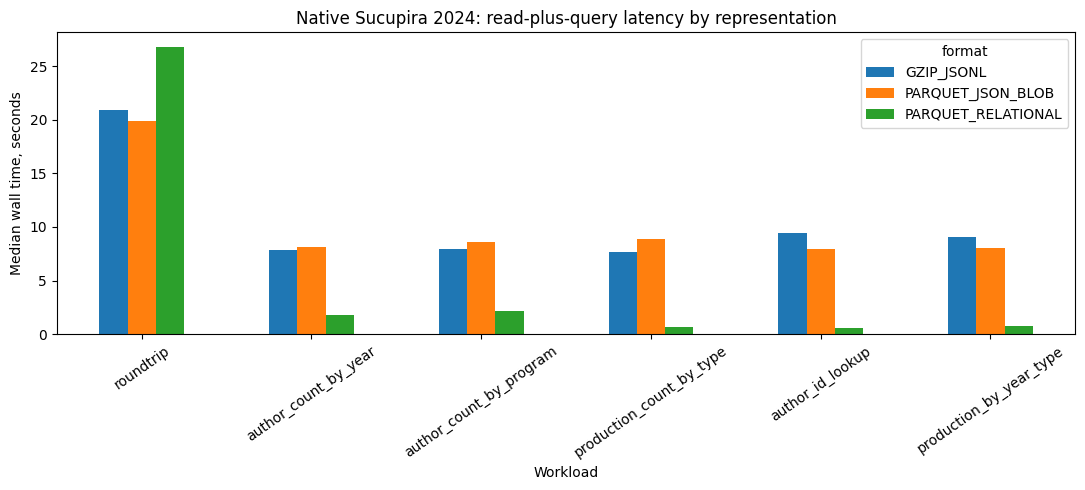

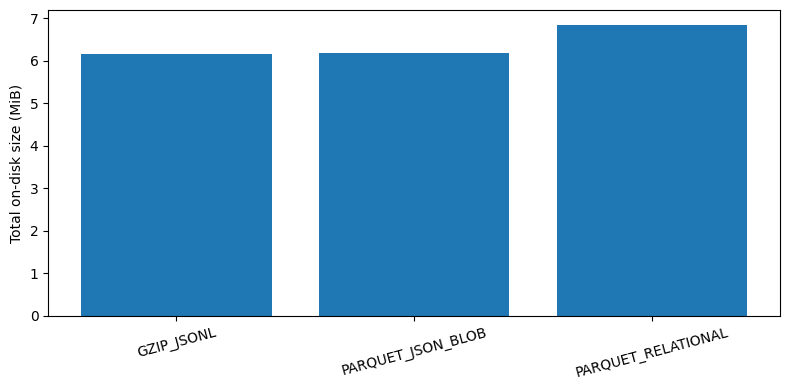

644851

In [ ]:
import matplotlib.pyplot as plt
FIG=OUT/'12_FIGURES';FIG.mkdir(exist_ok=True)
fig,ax=plt.subplots(figsize=(11,5))
timing=agg.pivot(index='task',columns='format',values='median_s').loc[TASKS]
timing.plot(kind='bar',ax=ax)
ax.set_ylabel('Median wall time, seconds');ax.set_xlabel('Workload');ax.set_title('Native Sucupira 2024: read-plus-query latency by representation')
ax.tick_params(axis='x',rotation=35);fig.tight_layout()
fig.savefig(FIG/'Figure_1_Workload_Timings.png',dpi=220,bbox_inches='tight')
fig.savefig(FIG/'Figure_1_Workload_Timings.pdf',bbox_inches='tight');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(list(sizes.keys()),[v/2**20 for v in sizes.values()]);ax.set_ylabel('Total on-disk size (MiB)')
ax.tick_params(axis='x',rotation=15);fig.tight_layout()
fig.savefig(FIG/'Figure_2_Storage.png',dpi=220,bbox_inches='tight');fig.savefig(FIG/'Figure_2_Storage.pdf',bbox_inches='tight');plt.show();plt.close(fig)
manifest=[]
for row in fileaudit.itertuples(index=False):
    p=SRC/row.relative
    manifest.append({'relative':row.relative,'sha256':file_sha256(p),'bytes':p.stat().st_size,'classification':row.classification})
(OUT/'13_SOURCE_SHA256_MANIFEST.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')

In [ ]:
import importlib.metadata
handoff={'status':'COMPLETED_WITH_SOURCE_COVERAGE_CAVEAT' if partial else 'COMPLETED_SOURCE_PARSE_CLEAN',
 'source':str(SRC),'year_scope':'2024 native extraction only','files_scanned':len(files),
 'files_with_partial_parse_or_read_error':len(partial),'records_recovered':sum(x['n_records_recovered'] for x in audit),
 'unique_content_records_benchmarked':N,'total_author_rows':len(authors),'all_roundtrips_correct':True,
 'python_tasks':TASKS,'python_repetitions_after_warmup':N_RUNS,'duckdb_tasks':sql_tasks,
 'disk_bytes':sizes,'seed':SEED,'cpu_only':True,
 'software':{'python':platform.python_version(),'pandas':pd.__version__,'pyarrow':pyarrow.__version__,
             'duckdb':duckdb.__version__,'numpy':np.__version__},
 'cautions':['partial JSONL extraction requires source-level reconciliation',
             'single 2024 snapshot; no 2013–2024 generalisation',
             'in-memory reconstruction in Python differs from SQL analytic engine',
             'tracemalloc excludes native Arrow allocation',
             'repetition bands represent runtime noise only',
             'private fields must not be published']}
(OUT/'14_FINAL_HANDOFF.json').write_text(json.dumps(handoff,indent=2,ensure_ascii=False),encoding='utf-8')
outputs=[]
for p in OUT.rglob('*'):
    if p.is_file() and p.name!='15_OUTPUT_SHA256_MANIFEST.json':outputs.append({'path':str(p.relative_to(OUT)),'sha256':file_sha256(p),'bytes':p.stat().st_size})
(OUT/'15_OUTPUT_SHA256_MANIFEST.json').write_text(json.dumps(outputs,indent=2),encoding='utf-8')
print('LAB-CJCS 04 COMPLETE:',OUT,' | files:',len(outputs),' | benchmarked:',N,' | partial-source files:',len(partial))

LAB-CJCS 04 COMPLETE: /content/drive/MyDrive/CAPES_Epistemic_Change/108_CJCS_NATIVE_SUCUPIRA_FULL_WORKLOAD_BENCHMARK_V1  | files: 17  | benchmarked: 62200  | partial-source files: 2
